In [1]:
## Import and Setup

In [1]:
import sys, pandas as pd
print(sys.version)
print("pandas:", pd.__version__)

3.12.15 (main, Oct  6 2026, 23:50:18) [GCC 15.3.0]
pandas: 2.3.3


In [2]:
%pip -q install pandas_datareader

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Download CPI from FRED and standardize the column name
import pandas_datareader.data as web
import pandas as pd

SERIES = "CPIAUCSL"          # CPI for All Urban Consumers, seasonally adjusted (monthly)
START  = "1990-01-01"
END    = "2025-12-31"        

df = web.DataReader(SERIES, "fred", START, END).dropna()
df = df.rename(columns={SERIES: "y"})
df.head(), df.tail(), df.shape

(                y
 DATE             
 1990-01-01  127.5
 1990-02-01  128.0
 1990-03-01  128.6
 1990-04-01  128.9
 1990-05-01  129.1,
                   y
 DATE               
 2025-07-01  322.169
 2025-08-01  323.291
 2025-09-01  324.245
 2025-11-01  325.063
 2025-12-01  326.031,
 (431, 1))

In [4]:
  df.to_csv("data/cpi_fred_1990_2025.csv")

In [5]:
# Force a clean monthly index
df = df.asfreq("MS")
print("Missing months:", df[df["y"].isna()].index.strftime("%Y-%m").tolist())

TEST_PERIODS = 24
train = df.iloc[:-TEST_PERIODS].copy()
test  = df.iloc[-TEST_PERIODS:].copy()

print("df freq:", df.index.freqstr)
print("train last:", train.index.max(), "test first:", test.index.min())
print("NaNs in train:", train["y"].isna().sum(), "| NaNs in test:", test["y"].isna().sum()) # leave missing months as NaN (do not fill)

Missing months: ['2025-10']
df freq: MS
train last: 2023-12-01 00:00:00 test first: 2024-01-01 00:00:00
NaNs in train: 0 | NaNs in test: 1


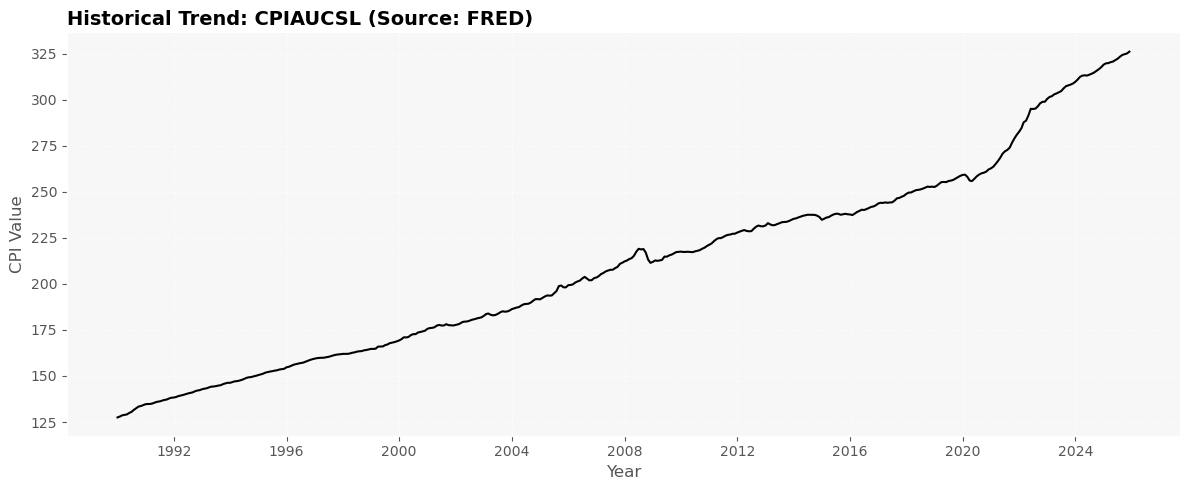

In [6]:
# Quick Plot
import os
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(x=df.index, y=df["y"], ax=ax, color="black", linewidth=1.5)

ax.set_title(f"Historical Trend: {SERIES} (Source: FRED)", fontweight='bold', loc='left', fontsize=14)
ax.set(xlabel="Year", ylabel="CPI Value", facecolor='#f7f7f7')
ax.grid(True, linestyle='--', alpha=0.5)

for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

os.makedirs("images", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.tight_layout()
plt.show()

In [7]:
# Time-based train/test split i.e. last 24 months
import numpy as np

TEST_PERIODS = 24

train = df.iloc[:-TEST_PERIODS].copy()
test  = df.iloc[-TEST_PERIODS:].copy()

print("Train:", train.index.min().date(), "->", train.index.max().date(), "rows:", len(train))
print("Test :", test.index.min().date(),  "->", test.index.max().date(),  "rows:", len(test))

Train: 1990-01-01 -> 2023-12-01 rows: 408
Test : 2024-01-01 -> 2025-12-01 rows: 24


In [8]:
## ARIMA

In [9]:
# Import ARIMA
from statsmodels.tsa.arima.model import ARIMA

In [10]:
# Fit ARIMA on Training Data
model = ARIMA(train["y"], order=(1,1,1))
arima_fit = model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  408
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -348.146
Date:                Fri, 06 Nov 2026   AIC                            702.291
Time:                        13:51:54   BIC                            714.318
Sample:                    01-01-1990   HQIC                           707.051
                         - 12-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6432      0.032     20.082      0.000       0.580       0.706
ma.L1          0.0582      0.044      1.321      0.187      -0.028       0.145
sigma2         0.3235      0.014     23.238      0.0

In [11]:
# Forecast Test Period
forecast = arima_fit.forecast(steps=len(test))
forecast = pd.Series(forecast, index=test.index)
forecast.head()

DATE
2024-01-01    309.139319
2024-02-01    309.395512
2024-03-01    309.560292
2024-04-01    309.666276
2024-05-01    309.734443
Freq: MS, Name: predicted_mean, dtype: float64

In [12]:
# Evaluate Performance (skips months with missing actuals)
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_forecast(y_true, y_pred, label="model"):
    y_true = pd.Series(np.asarray(y_true, dtype=float))
    y_pred = pd.Series(np.asarray(y_pred, dtype=float))
    k = y_true.notna() & y_pred.notna()
    mae  = mean_absolute_error(y_true[k], y_pred[k])
    rmse = np.sqrt(mean_squared_error(y_true[k], y_pred[k]))
    print(f"{label} MAE : {mae:.3f} | RMSE: {rmse:.3f} | n={int(k.sum())}")
    return mae, rmse

fc = arima_fit.get_forecast(steps=len(test))
forecast = fc.predicted_mean
forecast.index = test.index

arima_mae, arima_rmse = evaluate_forecast(
    test["y"].to_numpy(), forecast.to_numpy(), label="ARIMA(1,1,1)"
)

ARIMA(1,1,1) MAE : 7.881 | RMSE: 9.107 | n=23


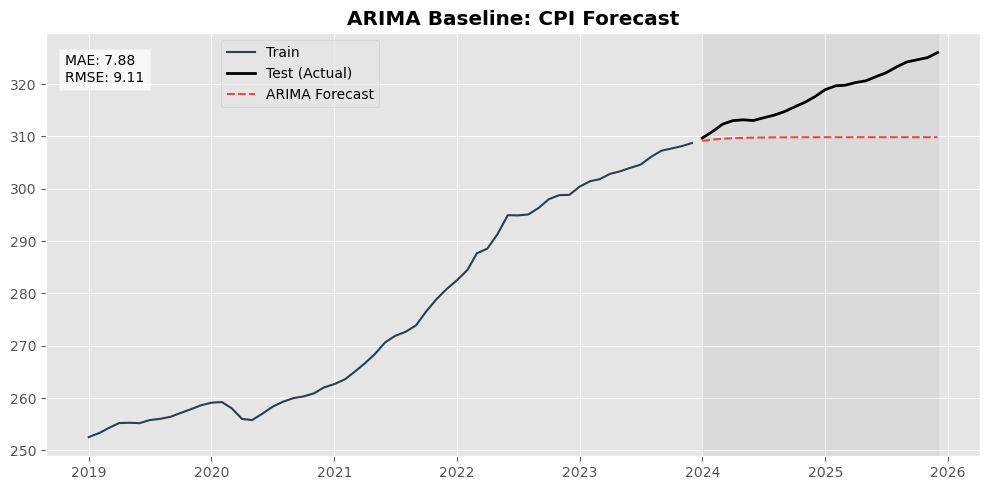

In [13]:
# Plot: train vs test vs forecast
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10, 5))

# Plot data (Zoomed to last 5 years of training for clarity)
sns.lineplot(x=train.index[-60:], y=train["y"].iloc[-60:], ax=ax, label="Train", color="#2c3e50")
sns.lineplot(x=test.index, y=test["y"], ax=ax, label="Test (Actual)", color="black", linewidth=2)
sns.lineplot(x=forecast.index, y=forecast, ax=ax, label="ARIMA Forecast", color="#e74c3c", linestyle="--")

# Highlights & Text
ax.axvspan(test.index[0], test.index[-1], color='gray', alpha=0.1)
ax.text(0.02, 0.95, f"MAE: {arima_mae:.2f}\nRMSE: {arima_rmse:.2f}", transform=ax.transAxes,
        va='top', bbox=dict(facecolor='white', alpha=0.7))

# Legend & Title
ax.set(xlabel="", ylabel="")
ax.legend(loc='upper left', bbox_to_anchor=(0.18, 1.0))  # Offset to avoid text box
ax.set_title("ARIMA Baseline: CPI Forecast", fontweight='bold')

plt.tight_layout()
plt.show()

In [14]:
# Create comparative results table
results = pd.DataFrame(columns=[
    "model",
    "mae",
    "rmse",
    "train_end",
    "test_start",
    "test_end"
])

results

,model,mae,rmse,train_end,test_start,test_end


In [15]:
# Add ARIMA Results
results.loc[len(results)] = [
    "ARIMA(1,1,1)",
    float(arima_mae),
    float(arima_rmse),
    train.index.max(),
    test.index.min(),
    test.index.max()
]

results

,model,mae,rmse,train_end,test_start,test_end
0,"ARIMA(1,1,1)",7.880555,9.106868,2023-12-01,2024-01-01,2025-12-01


In [16]:
## Prophet

In [17]:
%pip -q install prophet

Note: you may need to restart the kernel to use updated packages.


In [18]:
from prophet import Prophet

In [19]:
# Prepare data in prophet format
prophet_df = df.reset_index().rename(columns={"DATE": "ds", "y": "y"})
prophet_train = train.reset_index().rename(columns={"DATE": "ds", "y": "y"})
prophet_test  = test.reset_index().rename(columns={"DATE": "ds", "y": "y"})

prophet_train.head(), prophet_test.head()

(          ds      y
 0 1990-01-01  127.5
 1 1990-02-01  128.0
 2 1990-03-01  128.6
 3 1990-04-01  128.9
 4 1990-05-01  129.1,
           ds        y
 0 2024-01-01  309.698
 1 2024-02-01  310.967
 2 2024-03-01  312.345
 3 2024-04-01  313.023
 4 2024-05-01  313.175)

In [20]:
# Fit prophet
m = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)
m.fit(prophet_train)

13:52:30 - cmdstanpy - INFO - Chain [1] start processing
13:52:30 - cmdstanpy - INFO - Chain [1] done processing


In [21]:
# Forcast Test Dates
future = prophet_test[["ds"]].copy()
pred = m.predict(future)

prophet_forecast = pred.set_index("ds")["yhat"]
prophet_forecast.index = pd.to_datetime(prophet_forecast.index)

prophet_forecast.head(), prophet_forecast.tail()

(ds
 2024-01-01    301.610159
 2024-02-01    302.261756
 2024-03-01    303.406174
 2024-04-01    303.965109
 2024-05-01    304.746481
 Name: yhat, dtype: float64,
 ds
 2025-08-01    316.854227
 2025-09-01    317.815188
 2025-10-01    318.523265
 2025-11-01    319.039736
 2025-12-01    319.669884
 Name: yhat, dtype: float64)

In [22]:
# Evaluate
future = prophet_test[["ds"]].copy()
pred = m.predict(future)

prophet_forecast = pred.set_index("ds")["yhat"]
prophet_forecast.index = pd.to_datetime(prophet_forecast.index)

prophet_forecast.head(), prophet_forecast.tail()

prophet_mae, prophet_rmse = evaluate_forecast(
    test["y"].to_numpy(),
    prophet_forecast.reindex(test.index).to_numpy(),
    label="Prophet"
)

Prophet MAE : 7.110 | RMSE: 7.171 | n=23


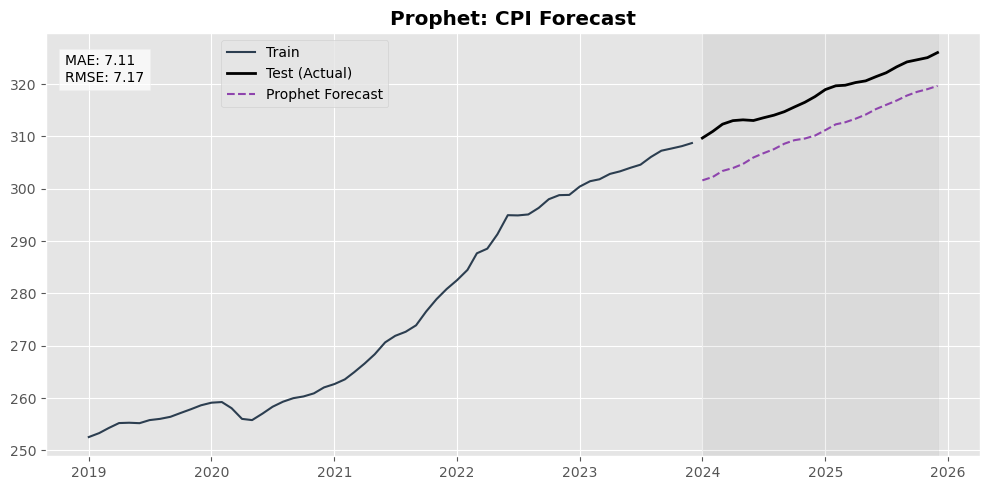

In [23]:
# Plot Comparison
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10, 5))

# Plot data
sns.lineplot(x=train.index[-60:], y=train["y"].iloc[-60:], ax=ax, label="Train", color="#2c3e50")
sns.lineplot(x=test.index, y=test["y"], ax=ax, label="Test (Actual)", color="black", linewidth=2)
sns.lineplot(x=prophet_forecast.index, y=prophet_forecast, ax=ax, label="Prophet Forecast", color="#8e44ad", linestyle="--")

# Highlights & Text
ax.axvspan(test.index[0], test.index[-1], color='gray', alpha=0.1)
ax.text(0.02, 0.95, f"MAE: {prophet_mae:.2f}\nRMSE: {prophet_rmse:.2f}", transform=ax.transAxes,
        va='top', bbox=dict(facecolor='white', alpha=0.7))

# Legend & Title
ax.set(xlabel="", ylabel="")
ax.legend(loc='upper left', bbox_to_anchor=(0.18, 1.0))
ax.set_title("Prophet: CPI Forecast", fontweight='bold')

plt.tight_layout()
plt.show()

In [24]:
# Add prophet to results table
results.loc[len(results)] = [
    "Prophet",
    float(prophet_mae),
    float(prophet_rmse),
    train.index.max(),
    test.index.min(),
    test.index.max()
]
results.sort_values("rmse") # sort by rmse

,model,mae,rmse,train_end,test_start,test_end
1,Prophet,7.109870,7.170765,2023-12-01,2024-01-01,2025-12-01
0,"ARIMA(1,1,1)",7.880555,9.106868,2023-12-01,2024-01-01,2025-12-01


In [25]:
## XGBoost 

In [26]:
# XGBoost: features and training
import xgboost as xgb

FULL = df["y"].diff()                               # monthly change in index points
LAGS = 12
feat = pd.concat({f"lag_{i}": FULL.shift(i) for i in range(1, LAGS + 1)}, axis=1)
data = feat.assign(target=FULL)

train_xy = data.loc[:train.index[-1]].dropna()
xgb_model = xgb.XGBRegressor(n_estimators=500, max_depth=3, learning_rate=0.01,
                             subsample=0.8, objective="reg:squarederror", random_state=42)
xgb_model.fit(train_xy.drop(columns="target"), train_xy["target"])

def score(y_true, y_pred, label):
    k = y_true.notna() & y_pred.notna()
    return dict(model=label,
                mae=mean_absolute_error(y_true[k], y_pred[k]),
                rmse=np.sqrt(mean_squared_error(y_true[k], y_pred[k])),
                n=int(k.sum()))
yt = test["y"]
print("xgboost:", xgb.__version__, "| training rows:", len(train_xy))

xgboost: 2.1.4 | training rows: 395


In [27]:
# 24 months ahead: same information for every model
hist = FULL.loc[:train.index[-1]].tail(LAGS).tolist()       # oldest -> newest
preds = []
for _ in range(len(test)):
    x = pd.DataFrame([hist[::-1][:LAGS]], columns=feat.columns)   # lag_1 = newest
    d = float(xgb_model.predict(x)[0]); preds.append(d); hist.append(d)
xgb_multi = train["y"].iloc[-1] + pd.Series(np.cumsum(preds), index=test.index)

h = np.arange(1, len(test) + 1)
naive = pd.Series(train["y"].iloc[-1], index=test.index)
drift = pd.Series(train["y"].iloc[-1] + train["y"].diff().tail(12).mean() * h, index=test.index)
arima_d = ARIMA(train["y"], order=(1,1,1), trend="t").fit()
arima_d_fc = pd.Series(arima_d.forecast(len(test)).to_numpy(), index=test.index)

multi = pd.DataFrame([
    score(yt, naive, "Naive (last value)"),
    score(yt, drift, "Drift (last 12-mo avg change)"),
    score(yt, forecast, "ARIMA(1,1,1)"),
    score(yt, arima_d_fc, "ARIMA(1,1,1) + drift"),
    score(yt, prophet_forecast.reindex(test.index), "Prophet"),
    score(yt, xgb_multi, "XGBoost (recursive)"),
]).sort_values("rmse").reset_index(drop=True)
multi

,model,mae,rmse,n
0,Drift (last 12-mo avg change),1.342435,1.514956,23
1,"ARIMA(1,1,1) + drift",3.420630,3.822974,23
2,XGBoost (recursive),3.905360,4.629748,23
3,Prophet,7.109870,7.170765,23
4,"ARIMA(1,1,1)",7.880555,9.106868,23
5,Naive (last value),8.909391,10.063388,23


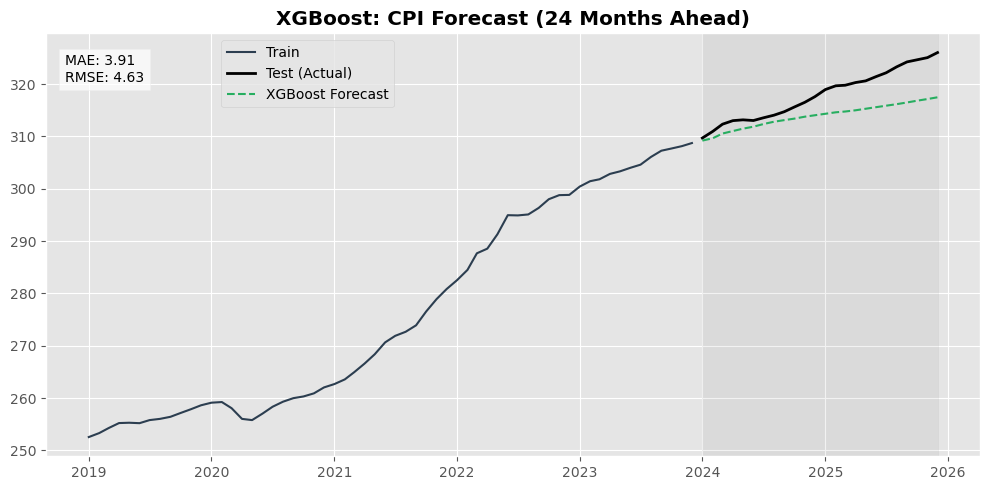

In [28]:
# Plot: XGBoost forecast
xgb_row = multi.loc[multi["model"] == "XGBoost (recursive)"].iloc[0]
xgb_mae, xgb_rmse = xgb_row["mae"], xgb_row["rmse"]

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10, 5))

# Plot data
sns.lineplot(x=train.index[-60:], y=train["y"].iloc[-60:], ax=ax, label="Train", color="#2c3e50")
sns.lineplot(x=test.index, y=test["y"], ax=ax, label="Test (Actual)", color="black", linewidth=2)
sns.lineplot(x=xgb_multi.index, y=xgb_multi, ax=ax, label="XGBoost Forecast", color="#27ae60", linestyle="--")

# Highlights & Text
ax.axvspan(test.index[0], test.index[-1], color='gray', alpha=0.1)
ax.text(0.02, 0.95, f"MAE: {xgb_mae:.2f}\nRMSE: {xgb_rmse:.2f}", transform=ax.transAxes,
        va='top', bbox=dict(facecolor='white', alpha=0.7))

# Legend & Title
ax.set(xlabel="", ylabel="")
ax.legend(loc='upper left', bbox_to_anchor=(0.18, 1.0))
ax.set_title("XGBoost: CPI Forecast (24 Months Ahead)", fontweight='bold')

plt.tight_layout()
plt.show()

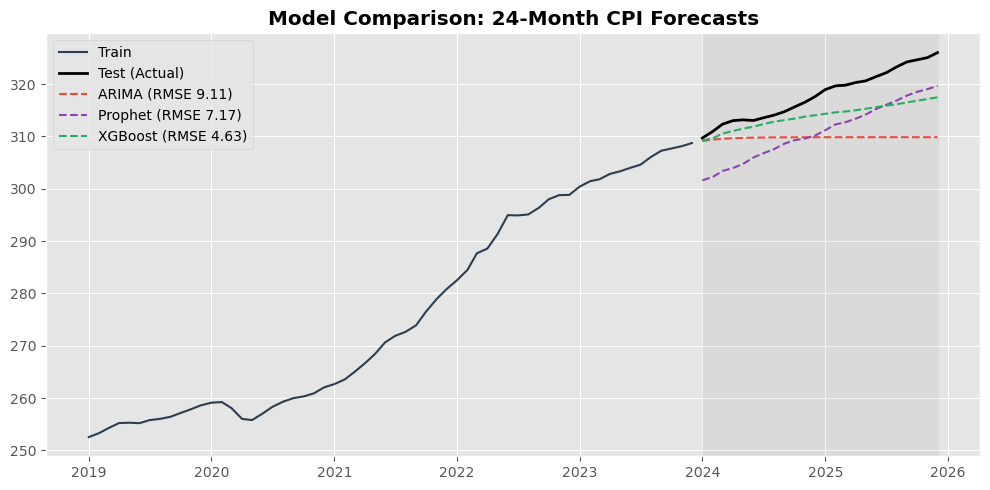

In [29]:
# Plot: model comparison (ARIMA, Prophet, XGBoost)
plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10, 5))

# Plot data
sns.lineplot(x=train.index[-60:], y=train["y"].iloc[-60:], ax=ax, label="Train", color="#2c3e50")
sns.lineplot(x=test.index, y=test["y"], ax=ax, label="Test (Actual)", color="black", linewidth=2)
sns.lineplot(x=forecast.index, y=forecast, ax=ax,
             label=f"ARIMA (RMSE {arima_rmse:.2f})", color="#e74c3c", linestyle="--")
sns.lineplot(x=prophet_forecast.index, y=prophet_forecast, ax=ax,
             label=f"Prophet (RMSE {prophet_rmse:.2f})", color="#8e44ad", linestyle="--")
sns.lineplot(x=xgb_multi.index, y=xgb_multi, ax=ax,
             label=f"XGBoost (RMSE {xgb_rmse:.2f})", color="#27ae60", linestyle="--")

# Highlights
ax.axvspan(test.index[0], test.index[-1], color='gray', alpha=0.1)

# Legend & Title
ax.set(xlabel="", ylabel="")
ax.legend(loc='upper left')
ax.set_title("Model Comparison: 24-Month CPI Forecasts", fontweight='bold')

plt.tight_layout()
fig.savefig("images/model_comparison_24m.png", dpi=200, bbox_inches="tight")
plt.show()

In [30]:
# 1 month ahead: how the deployed model is used
X_te = data.loc[test.index, feat.columns]
prev = df["y"].shift(1).loc[test.index]
xgb_1 = prev + pd.Series(xgb_model.predict(X_te), index=test.index)
arima_1 = arima_fit.append(test["y"], refit=False).get_prediction(start=test.index[0]).predicted_mean

one = pd.DataFrame([
    score(yt, prev, "Naive (last value)"),
    score(yt, arima_1, "ARIMA(1,1,1)"),
    score(yt, xgb_1, "XGBoost"),
]).sort_values("rmse").reset_index(drop=True)
one

,model,mae,rmse,n
0,XGBoost,0.374279,0.432124,22
1,"ARIMA(1,1,1)",0.393043,0.441815,23
2,Naive (last value),0.760636,0.845008,22


In [31]:
# 1 month ahead: score every model on the same months
common = yt.notna() & prev.notna() & xgb_1.notna() & arima_1.notna()
one = pd.DataFrame([
    score(yt[common], prev[common], "Naive (last value)"),
    score(yt[common], arima_1[common], "ARIMA(1,1,1)"),
    score(yt[common], xgb_1[common], "XGBoost"),
]).sort_values("rmse").reset_index(drop=True)
one

,model,mae,rmse,n
0,XGBoost,0.374279,0.432124,22
1,"ARIMA(1,1,1)",0.401412,0.449543,22
2,Naive (last value),0.760636,0.845008,22


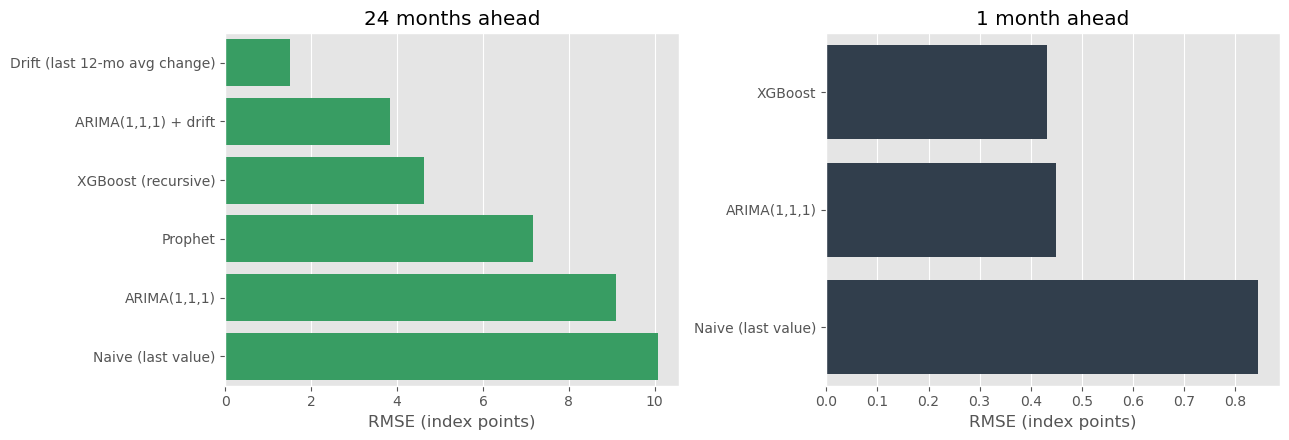

In [32]:
# RMSE comparison from the results tables
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=multi, y="model", x="rmse", ax=axes[0], color="#27ae60")
axes[0].set(xlabel="RMSE (index points)", ylabel="", title="24 months ahead")
sns.barplot(data=one, y="model", x="rmse", ax=axes[1], color="#2c3e50")
axes[1].set(xlabel="RMSE (index points)", ylabel="", title="1 month ahead")
plt.tight_layout()
fig.savefig("images/rmse_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
# Deployment and Packaging
import joblib
import tarfile
import os
import shutil

MODEL_DIR = "model_artifacts"
os.makedirs(MODEL_DIR, exist_ok=True)

# Save the XGBoost model
MODEL_PATH = os.path.join(MODEL_DIR, "xgboost_model.json")
xgb_model.save_model(MODEL_PATH)

# save the feature list (ensures inference data matches training)
FEATURES_PATH = os.path.join(MODEL_DIR, "features.pkl")
joblib.dump(feat.columns.tolist(), FEATURES_PATH)

# create the tarball for SageMaker deployment
TARBALL_PATH = "xgboost-model.tar.gz"
with tarfile.open(TARBALL_PATH, "w:gz") as tar:
    tar.add(MODEL_PATH, arcname="xgboost_model.json")
    tar.add(FEATURES_PATH, arcname="features.pkl")

#  Copy to the deploy folder used by deploy_cpi.ipynb
if os.path.isdir("cpi-deploy"):
    shutil.copy(TARBALL_PATH, "cpi-deploy/xgboost-model.tar.gz")

print(f"Created tarball: {TARBALL_PATH} | XGBoost {xgb.__version__} | features: {len(feat.columns)}")

Created tarball: xgboost-model.tar.gz | XGBoost 2.1.4 | features: 12
